# Video 6: Cross modality validation

Notes for this notebook.

This notebook generates the visuals for the sixth video in the Multimodal Spatial Biology series, the first video in our second arc. So far in this series, our biological conclusions have rested almost entirely on COMET protein data. Here we check whether an independent modality, Xenium transcripts, agrees with what CD45 protein told us, and what that comparison actually reveals.

This notebook reuses the quantification table saved by the Video 3 notebook, so run that one first if you have not already. All output images are saved into outputs/video6, next to this notebook.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline


In [3]:
from pathlib import Path

OUTPUT_DIR = Path("outputs/video6")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Output folder ready at:", OUTPUT_DIR.resolve())


Output folder ready at: C:\Users\m6sbhatt\Documents\Personal\python_projects\unumlocalia\outputs\video6


## Load the quantification table

We already have everything we need, this table has both COMET protein means and Xenium gene transcript counts, per cell, from Video 3. No new loading required.


In [4]:
df = pd.read_csv("outputs/video3/core01_hcc_quantification.csv")
print("Table shape:", df.shape)


Table shape: (8283, 5022)


## Checking for the CD45 gene, PTPRC

The gene that encodes CD45 is called PTPRC. Ideally, we would check CD45 protein directly against PTPRC transcript counts, same gene, two technologies. Xenium gene panels are curated in advance though, and not every gene makes it into every panel design.


In [5]:
print("PTPRC in this panel:", "PTPRC" in df.columns)


PTPRC in this panel: False


PTPRC is not in this particular gene panel. Rather than giving up on cross modality validation, we can check CD45 protein against other immune lineage genes that are present, T cell, myeloid, and general leukocyte markers. This will not be a same gene comparison, but it can still tell us something meaningful about immune identity.


In [6]:
from scipy.stats import spearmanr

immune_gene_candidates = ["PTPRC", "CD52", "CD3E", "CD3D", "CD7", "LYZ", "CD14", "ITGAM", "CD68"]
available = [g for g in immune_gene_candidates if g in df.columns]
print("Available immune gene candidates in this panel:", available)

results = []
for gene in available:
    corr, pval = spearmanr(df["CD45 - TRITC_mean"], df[gene])
    results.append((gene, corr, pval, df[gene].sum()))

results_df = pd.DataFrame(results, columns=["gene", "spearman_r", "p_value", "total_transcripts"])
results_df = results_df.sort_values("spearman_r", ascending=False).reset_index(drop=True)
print(results_df)


Available immune gene candidates in this panel: ['CD3E', 'CD7', 'CD14', 'ITGAM', 'CD68']
    gene  spearman_r        p_value  total_transcripts
0   CD3E    0.384262  1.165133e-289               2179
1  ITGAM    0.015309   1.635823e-01                129
2    CD7    0.007640   4.869152e-01                788
3   CD14   -0.053597   1.057283e-06                739
4   CD68   -0.071696   6.467916e-11               1259


## Reading the result honestly

CD3E, a T cell specific gene, shows a moderate, highly significant correlation with CD45 protein. The myeloid markers, CD14 and CD68, show essentially no correlation, if anything, a very slight negative one.

This is not a failure of the two modalities to agree. CD45 protein is a pan leukocyte marker, it appears on nearly every white blood cell type, T cells, B cells, and myeloid cells alike. It cannot tell us what kind of immune cell we are looking at. The fact that a T cell specific transcript correlates while myeloid transcripts do not is actually new information, it suggests the immune aggregate we have been looking at throughout this series is predominantly T cell driven, not macrophage driven, something CD45 protein alone could never have told us.

A moderate correlation, rather than a strong one, is also expected here. Spatial transcriptomics has real per cell transcript sparsity, a cell can genuinely express a gene and still show a low or zero detected count, purely from technical sensitivity limits, not biological absence.


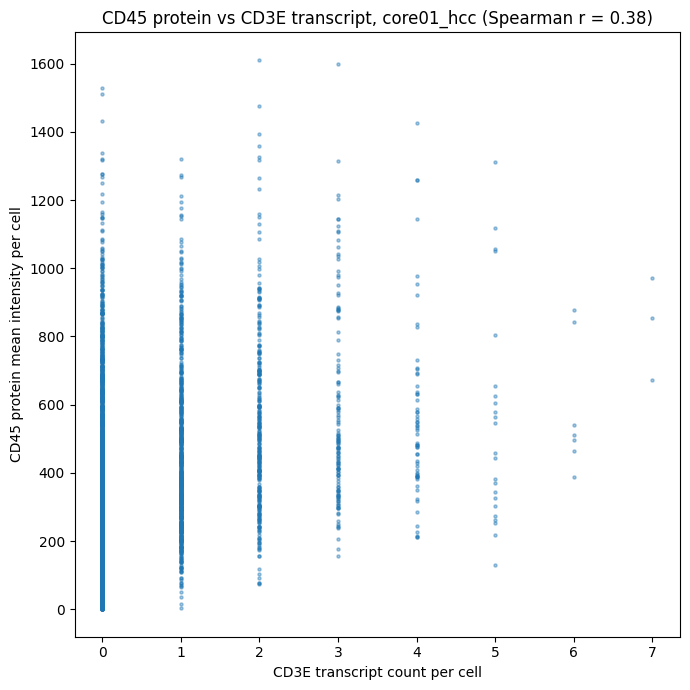

Saved slide_cd45_vs_cd3e_scatter.png


In [7]:
best_gene = results_df.iloc[0]["gene"]
best_corr = results_df.iloc[0]["spearman_r"]

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(df[best_gene], df["CD45 - TRITC_mean"], s=5, alpha=0.4)
ax.set_xlabel(f"{best_gene} transcript count per cell")
ax.set_ylabel("CD45 protein mean intensity per cell")
ax.set_title(f"CD45 protein vs {best_gene} transcript, core01_hcc (Spearman r = {best_corr:.2f})")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "slide_cd45_vs_cd3e_scatter.png", dpi=200, facecolor="white")
plt.show()

print(f"Saved slide_cd45_vs_cd3e_scatter.png")


## Confirming the spatial pattern independently

A correlation across all cells is one kind of evidence. Seeing the same spatial pattern emerge from a completely independent measurement is a more convincing kind. Here we plot CD3E transcript counts spatially, with no reference to CD45 at all, and see whether it lands in the same place.


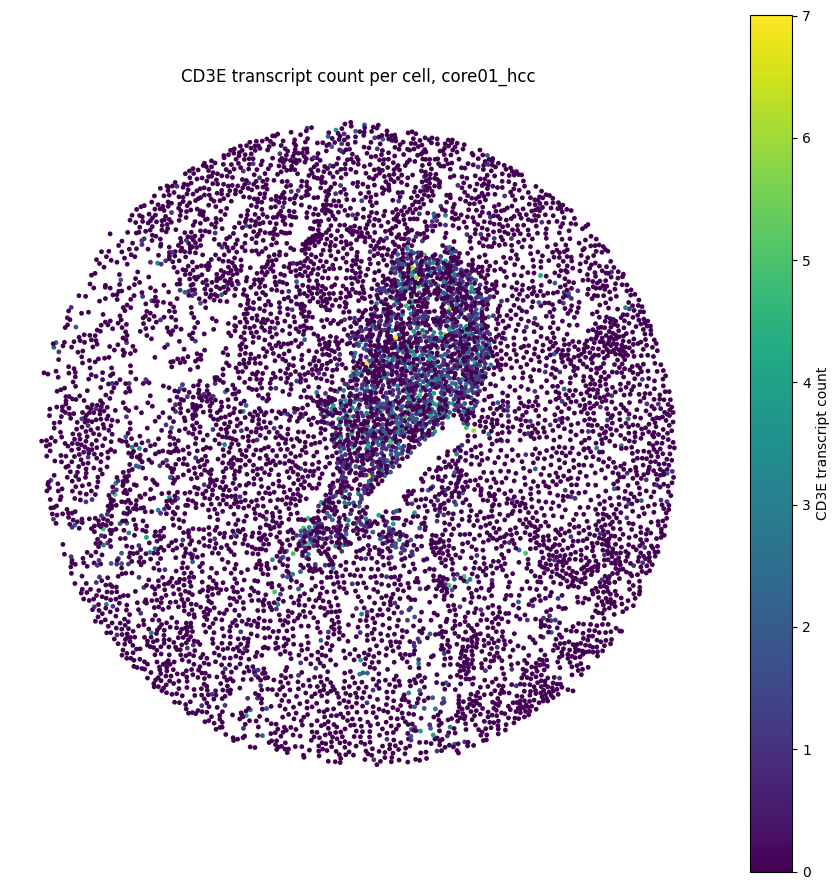

Saved slide_cd3e_spatial.png


In [8]:
fig, ax = plt.subplots(figsize=(9, 9))
sc = ax.scatter(df["centroid_x"], df["centroid_y"], c=df[best_gene], cmap="viridis", s=6)
ax.invert_yaxis()
ax.set_aspect("equal")
ax.axis("off")
ax.set_title(f"{best_gene} transcript count per cell, core01_hcc")
plt.colorbar(sc, ax=ax, label=f"{best_gene} transcript count")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "slide_cd3e_spatial.png", dpi=200, facecolor="white")
plt.show()

print("Saved slide_cd3e_spatial.png")


## Summary

CD3E transcript signal concentrates in the same physical location as the CD45 protein aggregate we have referenced throughout this series, confirmed independently, with no shared processing between the two measurements beyond both coming from the same physical cells. Protein data told us immune cells were present and where. Transcript data told us what kind, predominantly T cell, and confirmed the same spatial location entirely on its own.

This is the first point in the series where combining modalities produced a conclusion that neither one could have reached alone.

Next episode, we take this further. Rather than looking at one marker at a time, we let all sixteen COMET markers together define cell populations through unsupervised clustering, and see what that reveals.
